# Decision trees: from questions to predictions 🌳

**Level:** beginner → moderate · **Time:** about 30–40 minutes · **Works in:** Google Colab

In this notebook, you will:
1. Understand how a tree chooses questions and makes predictions.
2. Train a **classifier** to predict an Iris flower's species.
3. Train a **regressor** to predict a numerical diabetes progression measure.
4. Compare training, validation, and test performance without mixing up their jobs.

Run cells from top to bottom using **Runtime → Run all**, or press **Shift + Enter** on each cell. The real datasets are bundled with scikit-learn, so no data download or API key is needed. The notebook uses only scikit-learn, pandas, NumPy, and Matplotlib.

## 1 · The idea: a flowchart learned from examples

Suppose we measure a flower. A tree might ask **“Is petal length ≤ 2.5 cm?”** The answer sends the flower down one branch. Another question may follow. A final **leaf** gives a prediction.

| Part | What it does |
|---|---|
| **Feature** | An input clue, such as petal length |
| **Root** | The tree's first question |
| **Branch** | The path chosen by an answer |
| **Leaf** | The final prediction |

A tree *learns* which questions to ask by trying possible splits of its **training data**. It prefers splits that make the resulting groups more alike in their target values.

**Classification** predicts a category (for example, flower species). **Regression** predicts a number (for example, a disease progression score). The tree structure is the same; its split score and leaf prediction differ.

### How does the tree choose a question?

For classification, **Gini impurity** describes how mixed the classes are in a group:

$$Gini = 1 - \sum_{k=1}^{K} p_k^2$$

Here $p_k$ is the fraction in class $k$. A pure group scores **0**. A group with equal numbers of two classes scores **0.5**. The algorithm prefers a split with a low **size-weighted average impurity** across its two children.

For regression, a common split score is **mean squared error (MSE)**: how far the numbers in each child are from that child's mean. A regression leaf predicts its training examples' **mean target value**. A classification leaf predicts its **most common class**.

In [18]:
def gini(labels):
    return 1 - sum((labels.count(label) / len(labels)) ** 2
                   for label in set(labels))

print("Two of each class:", gini(["A", "A", "B", "B"]))
print("All one class:   ", gini(["A", "A", "A", "A"]))

Two of each class: 0.5
All one class:    0.0


<details>
<summary><strong>Check your intuition: why is a group of only A's appealing?</strong></summary>

Its Gini score is 0. If a tree reaches this group, it can predict A without ambiguity among those training examples. It still needs a separate check on unseen data.

</details>

## 2 · Classification with the real Iris dataset

The Iris dataset has **150 flowers**, **four measurements in centimeters**, and **three species**: setosa, versicolor, and virginica. We will predict species from the measurements.

First, import the tools used in both examples. `random_state=42` later makes the random split reproducible.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import (
    accuracy_score, ConfusionMatrixDisplay, confusion_matrix, mean_absolute_error, r2_score
)

In [20]:
iris = load_iris(as_frame=True)
X = iris.data          # 4 measurements: the clues
y = iris.target        # species number: 0, 1, or 2

print("Rows and features:", X.shape)
print("Species:", list(iris.target_names))
display(X.assign(species=y.map(dict(enumerate(iris.target_names)))).head())

Rows and features: (150, 4)
Species: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Step A · Set aside data for an honest check

- **Training (90 flowers):** learn tree questions.
- **Validation (30 flowers):** choose the depth limit.
- **Test (30 flowers):** check the chosen tree once, after choosing its depth.

`stratify=y` keeps the species proportions similar in each split. Never train on the test rows or choose depth from their scores.

In [21]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.25, random_state=42, stratify=y_train_full
)

print("Training:", len(X_train), "Validation:", len(X_val), "Test:", len(X_test))

Training: 90 Validation: 30 Test: 30


### Step B · Fit a small tree, then read it

`max_depth=2` allows at most two questions along any path. `min_samples_leaf=3` requires at least three training flowers at a leaf. These limits help prevent overly specific rules.

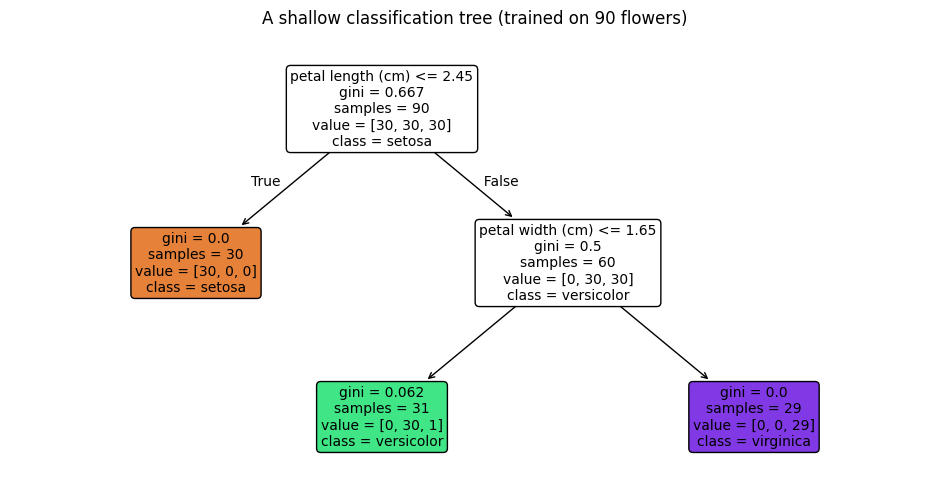

In [22]:
small_clf = DecisionTreeClassifier(
    max_depth=2, min_samples_leaf=3, random_state=42
)
small_clf.fit(X_train, y_train)

plt.figure(figsize=(12, 6))
plot_tree(
    small_clf, feature_names=X.columns, class_names=iris.target_names,
    filled=True, rounded=True, fontsize=10
)
plt.title("A shallow classification tree (trained on 90 flowers)")
plt.show()

**Read the diagram:** start at the top. If the question is true (`≤`), go **left**; otherwise go **right**. `samples` counts training flowers at the node, `value` counts each species, and `class` is the predicted species. Colors show the dominant class; more saturated nodes tend to be purer.

Try tracing a flower with a short petal from root to leaf. The exact thresholds are learned from these particular training rows.

### Step C · Choose depth using validation flowers

A deeper tree can fit training rows more closely, but that does not guarantee a better prediction on new flowers. We compare a few depth limits on **validation** rows, choosing the first (shallowest) depth in a tie.

In [23]:
clf_results = []
for depth in [1, 2, 3, 4, 5]:
    model = DecisionTreeClassifier(
        max_depth=depth, min_samples_leaf=3, random_state=42
    )
    model.fit(X_train, y_train)
    clf_results.append({
        "depth": depth,
        "training_accuracy": accuracy_score(y_train, model.predict(X_train)),
        "validation_accuracy": accuracy_score(y_val, model.predict(X_val)),
    })

clf_scores = pd.DataFrame(clf_results)
display(clf_scores.round(3))

best_clf_depth = int(clf_scores.loc[clf_scores.validation_accuracy.idxmax(), "depth"])
print("Selected depth:", best_clf_depth)

,depth,training_accuracy,validation_accuracy
0,1,0.667,0.667
1,2,0.989,0.900
2,3,0.989,0.900
3,4,0.989,0.900
4,5,0.989,0.900


Selected depth: 2


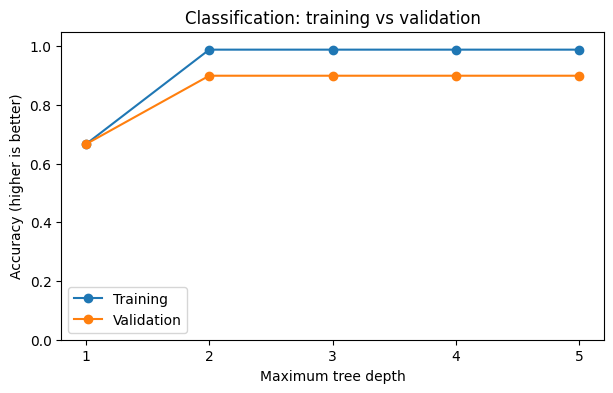

In [24]:
plt.figure(figsize=(7, 4))
plt.plot(clf_scores.depth, clf_scores.training_accuracy, "o-", label="Training")
plt.plot(clf_scores.depth, clf_scores.validation_accuracy, "o-", label="Validation")
plt.xticks(clf_scores.depth)
plt.ylim(0, 1.05)
plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy (higher is better)")
plt.title("Classification: training vs validation")
plt.legend()
plt.show()

### Step D · Retrain and evaluate once on held-out data

Now that depth is chosen, use **training + validation** rows to fit the final model. Accuracy is the fraction predicted correctly. The confusion matrix shows *which* species were confused; rows are actual species and columns are predicted species.

Test accuracy: 0.933


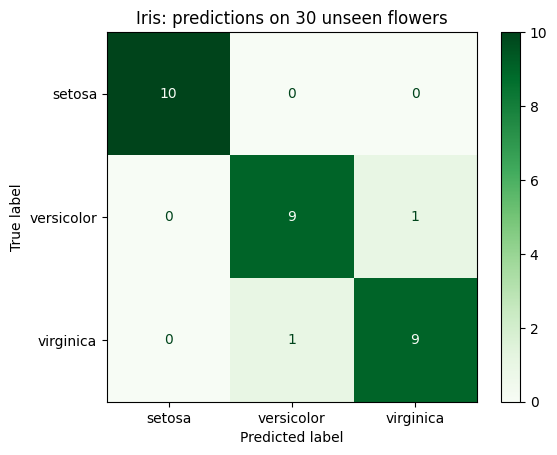

In [25]:
classifier = DecisionTreeClassifier(
    max_depth=best_clf_depth, min_samples_leaf=3, random_state=42
)
classifier.fit(X_train_full, y_train_full)
class_predictions = classifier.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, class_predictions), 3))
ConfusionMatrixDisplay.from_predictions(
    y_test, class_predictions, display_labels=iris.target_names, cmap="Greens"
)
plt.title("Iris: predictions on 30 unseen flowers")
plt.show()

### What are TP, TN, FP, and FN here?

The Iris task has **three species**. These four terms describe a **binary** question, so we ask it separately for each species: **“Is this flower this species, or one of the other two?”** This is called *one-versus-rest*.

- **TP (true positive):** this species, correctly predicted as this species.
- **TN (true negative):** another species, correctly predicted as another species.
- **FP (false positive):** another species, incorrectly predicted as this species.
- **FN (false negative):** this species, incorrectly predicted as another species.

For example, in the **versicolor** panel, “positive” means versicolor and “negative” means either setosa or virginica. Each panel contains all **30 test flowers**. Read **rows as actual** and **columns as predicted**.


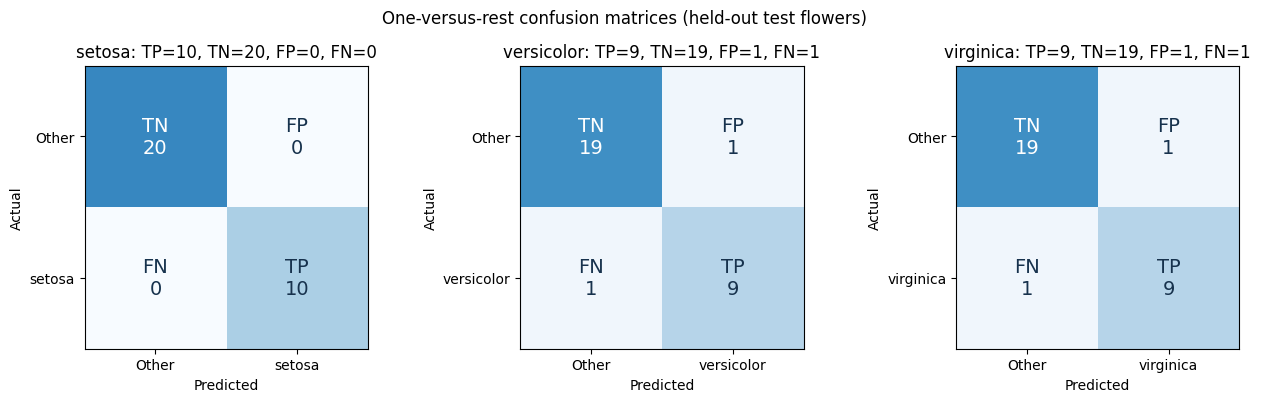

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
markers = [["TN", "FP"], ["FN", "TP"]]

for species_id, (species, ax) in enumerate(zip(iris.target_names, axes)):
    actual_is_species = (y_test == species_id)
    predicted_is_species = (class_predictions == species_id)

    # Rows: actual Other / This species; columns: predicted Other / This species
    matrix = confusion_matrix(
        actual_is_species, predicted_is_species, labels=[False, True]
    )
    tn, fp, fn, tp = matrix.ravel()

    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=len(y_test))
    for row in range(2):
        for col in range(2):
            value = matrix[row, col]
            ax.text(col, row, f"{markers[row][col]}\n{value}",
                    ha="center", va="center", fontsize=14,
                    color="white" if value > len(y_test) / 2 else "#17324d")
    ax.set_xticks([0, 1], ["Other", species])
    ax.set_yticks([0, 1], ["Other", species])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{species}: TP={tp}, TN={tn}, FP={fp}, FN={fn}")

fig.suptitle("One-versus-rest confusion matrices (held-out test flowers)")
plt.tight_layout()
plt.show()


In [27]:
flower = X_test.iloc[[0]]  # keep the DataFrame columns and one row
guess = classifier.predict(flower)[0]
print("Flower measurements (cm):")
display(flower)
print("Predicted:", iris.target_names[guess])
print("Actual:   ", iris.target_names[y_test.iloc[0]])

Flower measurements (cm):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
38,4.4,3.0,1.3,0.2


Predicted: setosa
Actual:    setosa


<details>
<summary><strong>Classification check: why is a 100% training score not enough?</strong></summary>

An overly deep tree might memorize training rows. Validation and test data reveal whether its rules generalize. Use validation to select settings and keep test data aside until the model is chosen.

</details>

## 3 · Regression with the real Diabetes dataset

Now the target is a **number**, so this is a regression task. The scikit-learn Diabetes dataset has **442 patients**. Its ten input features are standardized measurements, and its target is a quantitative measure of **disease progression one year later**. This dataset is for learning the method, not medical use.

The tree still asks questions such as “Is this feature ≤ some threshold?” But a leaf predicts the **mean target** of its training patients, and splits aim to reduce squared error within the resulting groups.

`s1` –`s6` are blood measurements:
- s1: total cholesterol
- s2: LDL cholesterol
- s3: HDL cholesterol
- s4: total cholesterol ÷ HDL
- s5: possibly the log of triglyceride levels
- s6: blood sugar

The values are scaled, so they are not in the original measurement units.

In [28]:
diabetes = load_diabetes(as_frame=True)
X_reg = diabetes.data
y_reg = diabetes.target

print("Rows and features:", X_reg.shape)
print("Target range:", y_reg.min(), "to", y_reg.max())
display(X_reg.head())

Rows and features: (442, 10)
Target range: 25.0 to 346.0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


**Note:** these feature values are already scaled in the supplied dataset. For example, `bmi` here is a standardized feature, not a BMI value in its usual units. Tree models generally do not require feature scaling, but we keep the dataset as provided.

### Step A · Make training, validation, and test sets

The target is continuous, so there is no species class to stratify by. We keep 20% as test data, then take 25% of the remainder for validation.

In [29]:
Xr_train_full, Xr_test, yr_train_full, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)
Xr_train, Xr_val, yr_train, yr_val = train_test_split(
    Xr_train_full, yr_train_full, test_size=0.25, random_state=42
)

print("Training:", len(Xr_train), "Validation:", len(Xr_val), "Test:", len(Xr_test))

Training: 264 Validation: 89 Test: 89


### Step B · Choose depth with validation error

Here the metric is **mean absolute error (MAE)**: the average absolute difference between a prediction and the true value. **Lower is better.** We keep `min_samples_leaf=5` to avoid leaves based on only one patient.

In [30]:
reg_results = []
for depth in [1, 2, 3, 4, 5, 6]:
    model = DecisionTreeRegressor(
        max_depth=depth, min_samples_leaf=5, random_state=42
    )
    model.fit(Xr_train, yr_train)
    reg_results.append({
        "depth": depth,
        "training_MAE": mean_absolute_error(yr_train, model.predict(Xr_train)),
        "validation_MAE": mean_absolute_error(yr_val, model.predict(Xr_val)),
    })

reg_scores = pd.DataFrame(reg_results)
display(reg_scores.round(1))

best_reg_depth = int(reg_scores.loc[reg_scores.validation_MAE.idxmin(), "depth"])
print("Selected depth:", best_reg_depth)

,depth,training_MAE,validation_MAE
0,1,53.6,54.9
1,2,47.2,46.7
2,3,42.8,46.9
3,4,39.0,48.8
4,5,33.0,50.9
5,6,29.9,51.1


Selected depth: 2


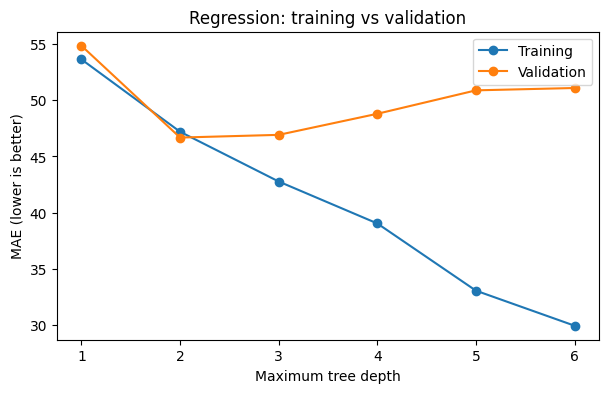

In [31]:
plt.figure(figsize=(7, 4))
plt.plot(reg_scores.depth, reg_scores.training_MAE, "o-", label="Training")
plt.plot(reg_scores.depth, reg_scores.validation_MAE, "o-", label="Validation")
plt.xticks(reg_scores.depth)
plt.xlabel("Maximum tree depth")
plt.ylabel("MAE (lower is better)")
plt.title("Regression: training vs validation")
plt.legend()
plt.show()

### Step C · Retrain, compare with a baseline, and test

A baseline that predicts the **training mean** for every patient gives the MAE a reference point. We also report **$R^2$**: 1 is perfect; 0 corresponds to always predicting the mean of the evaluated targets; negative values perform worse than that reference. A baseline using the *training* mean need not score exactly 0 on held-out data.

In [32]:
regressor = DecisionTreeRegressor(
    max_depth=best_reg_depth, min_samples_leaf=5, random_state=42
)
regressor.fit(Xr_train_full, yr_train_full)
reg_predictions = regressor.predict(Xr_test)

baseline_predictions = np.full(len(yr_test), yr_train_full.mean())  # return mean of target variable for each feature input
print("Baseline test MAE:", round(mean_absolute_error(yr_test, baseline_predictions), 1))
print("Tree test MAE:    ", round(mean_absolute_error(yr_test, reg_predictions), 1))
print("Tree test R²:     ", round(r2_score(yr_test, reg_predictions), 3))

Baseline test MAE: 64.0
Tree test MAE:     49.4
Tree test R²:      0.295


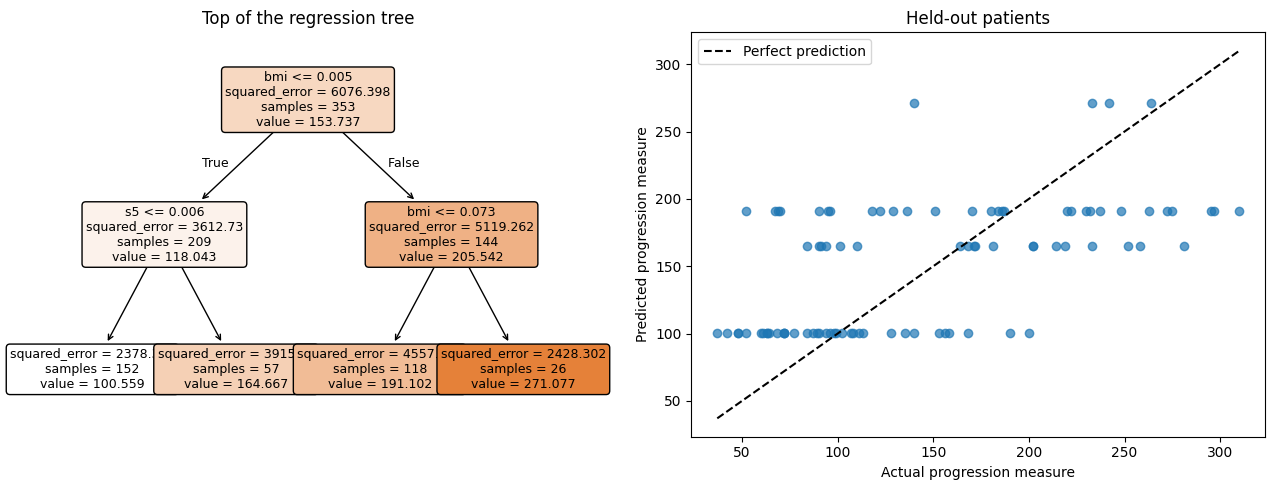

In [33]:
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plot_tree(regressor, feature_names=X_reg.columns, filled=True,
          rounded=True, max_depth=2, fontsize=9)
plt.title("Top of the regression tree")

plt.subplot(1, 2, 2)
plt.scatter(yr_test, reg_predictions, alpha=0.7)
plt.plot([yr_test.min(), yr_test.max()],
         [yr_test.min(), yr_test.max()], "k--", label="Perfect prediction")
plt.xlabel("Actual progression measure")
plt.ylabel("Predicted progression measure")
plt.title("Held-out patients")
plt.legend()
plt.tight_layout()
plt.show()

The left diagram shows at most two levels so its text stays readable; if the final tree is deeper, `(...)` marks hidden branches. In the scatter plot, points near the dashed line have smaller errors. A regression tree produces a **stepwise** prediction: patients reaching the same leaf get the same numerical prediction.

In [34]:
patient = Xr_test.iloc[[0]]
print("Predicted progression measure:", round(regressor.predict(patient)[0], 1))
print("Actual progression measure:   ", yr_test.iloc[0])
print("Reached leaf number:         ", regressor.apply(patient)[0])

Predicted progression measure: 164.7
Actual progression measure:    219.0
Reached leaf number:          3


<details>
<summary><strong>Regression check: why is a lower validation MAE better?</strong></summary>

MAE is the average size of the prediction errors in the target's units. Smaller errors mean predictions are, on average, closer to the held-out validation values. The final test set is evaluated only after choosing depth.

</details>

## 4 · Put the two tasks side by side

| Question | Classification tree | Regression tree |
|---|---|---|
| Predicts | A **category** | A **number** |
| Example target | Iris species | Diabetes progression measure |
| Typical split goal | Reduce class impurity (such as Gini) | Reduce numerical spread (such as MSE) |
| Leaf prediction | Most common class | Mean target value |
| Metric we used | Accuracy + confusion matrix | MAE + $R^2$ |

**Benefits:** trees are easy to trace, model nonlinear rules, and need little feature scaling. **Limitations:** deep trees may overfit, small data changes may alter the rules, and a single tree can be less accurate than a well-tuned ensemble. Depth and minimum leaf size are simple ways to control complexity.

### Try it yourself

1. Change `min_samples_leaf` from 3 to 5 in the Iris cells. Which depth wins on validation?
2. Change `min_samples_leaf` from 5 to 10 in the Diabetes cells. Does validation MAE change?
3. In the Iris plot, follow one question from root to leaf. Which measurements matter along that path?

**Keep the evaluation order:** train on training rows → choose settings with validation rows → fit on training + validation rows → check once on test rows. If you tune repeatedly using the test result, reserve a new untouched test set for an honest final estimate.

**Dataset provenance:** both datasets are loaded from scikit-learn's built-in datasets. Iris contains Fisher's flower measurements; the Diabetes dataset is the 442-patient benchmark described in Efron and colleagues' *Least Angle Regression* (2004). The notebook does not fetch data from external sites.